## Первичный анализ данных

Проанализируем структуру данных, целевую переменную, пропуски, основные статистики, категориальные признаки и выявим потенциальные выборосы и аномальные значения

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('../data/raw/train.csv')
target = 'Credit Default'

print(f'Размер: {df.shape[0]:,} строк и {df.shape[1]} столбцов')
display(df.head())
display(df.dtypes.rename('Тип данных').to_frame())
print(f'Полных дубликатов строк: {df.duplicated().sum()}')

Размер: 7,500 строк и 17 столбцов


,Home Ownership,Annual Income,Years in current job,Tax Liens,Number of Open Accounts,Years of Credit History,Maximum Open Credit,Number of Credit Problems,Months since last delinquent,Bankruptcies,Purpose,Term,Current Loan Amount,Current Credit Balance,Monthly Debt,Credit Score,Credit Default
0,Own Home,482087.0,NaN,0.0,11.0,26.3,685960.0,1.0,NaN,1.0,debt consolidation,Short Term,99999999.0,47386.0,7914.0,749.0,0
1,Own Home,1025487.0,10+ years,0.0,15.0,15.3,1181730.0,0.0,NaN,0.0,debt consolidation,Long Term,264968.0,394972.0,18373.0,737.0,1
2,Home Mortgage,751412.0,8 years,0.0,11.0,35.0,1182434.0,0.0,NaN,0.0,debt consolidation,Short Term,99999999.0,308389.0,13651.0,742.0,0
3,Own Home,805068.0,6 years,0.0,8.0,22.5,147400.0,1.0,NaN,1.0,debt consolidation,Short Term,121396.0,95855.0,11338.0,694.0,0
4,Rent,776264.0,8 years,0.0,13.0,13.6,385836.0,1.0,NaN,0.0,debt consolidation,Short Term,125840.0,93309.0,7180.0,719.0,0


,Тип данных
Home Ownership,object
Annual Income,float64
Years in current job,object
Tax Liens,float64
Number of Open Accounts,float64
Years of Credit History,float64
Maximum Open Credit,float64
Number of Credit Problems,float64
Months since last delinquent,float64
Bankruptcies,float64


Полных дубликатов строк: 0


## Целевая переменная - `Credit Default`

Рассмотрим соотношение классов целевой переменной

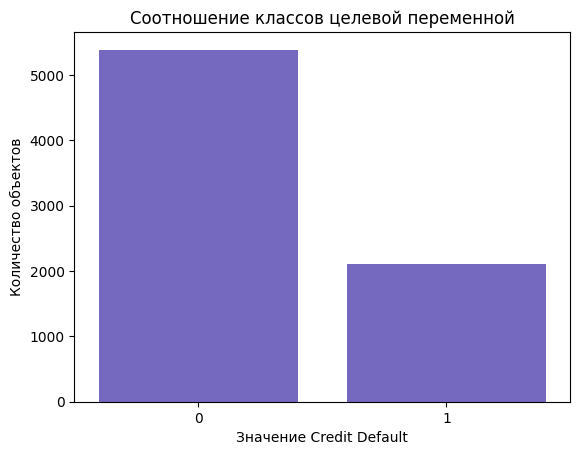

Количество строк, принадлежащих к нулевому классу 5387
Количество строк, принадлежащих к первому классу 2113


In [2]:
ax = sns.countplot(data=df, x='Credit Default', order=df['Credit Default'].value_counts().index, color='slateblue')
ax.set(title='Соотношение классов целевой переменной', xlabel='Значение Credit Default', ylabel='Количество объектов')
plt.show()
print(f'Количество строк, принадлежащих к нулевому классу {(df['Credit Default'] == 0).sum()}')
print(f'Количество строк, принадлежащих к первому классу {(df['Credit Default'] == 1).sum()}')

**Вывод по целевой переменной**: имеется заментный дисбаланс классов. При построении моделей будем это учитывать и подберем оптимальный метод борьбы с несбалансированностью.

## Пропущенные значения

,Пропуски,"Доля, %"
Months since last delinquent,4081,54.413333
Annual Income,1557,20.760000
Credit Score,1557,20.760000
Years in current job,371,4.946667
Bankruptcies,14,0.186667


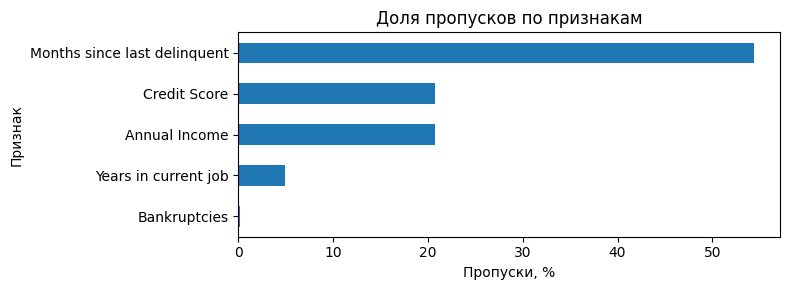

In [3]:
missing = pd.DataFrame({
    'Пропуски': df.isna().sum(),
    'Доля, %': df.isna().mean().mul(100),
})
missing = missing.loc[missing['Пропуски'].gt(0)].sort_values('Пропуски', ascending=False)
display(missing)

ax = missing['Доля, %'].sort_values().plot.barh(figsize=(8, 3))
ax.set(title='Доля пропусков по признакам', xlabel='Пропуски, %', ylabel='Признак')
plt.tight_layout()
plt.show()

**Вывод по пропускам.** Пропуски обнаружены в `Months since last delinquent` (4081, 53.41%), `Credit Score` (1557; 20.76%), `Annual Income` (1557; 20.76%), `Years in current job` (371, 4.95%) и `Bankruptcies` (14, 0.19%). В остальных столбцах пропусков нет. Заметим, что количество пропусков в признаках `Credit Score` и `Annual Income` одинаково. Вероятно, пропуски в данных признаках будут носить неслучайный характер. 

## Базовые статистики числовых признаков

Посмотрим на основные статистики числевых признаков

In [4]:
numeric_features = df.select_dtypes(include='number').columns
display(df[numeric_features].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2))

,Annual Income,Tax Liens,Number of Open Accounts,Years of Credit History,Maximum Open Credit,Number of Credit Problems,Months since last delinquent,Bankruptcies,Current Loan Amount,Current Credit Balance,Monthly Debt,Credit Score,Credit Default
count,5943.00,7500.00,7500.00,7500.00,7.500000e+03,7500.00,3419.00,7486.00,7500.00,7500.00,7500.00,5943.00,7500.00
mean,1366391.72,0.03,11.13,18.32,9.451537e+05,0.17,34.69,0.12,11873177.45,289833.24,18314.45,1151.09,0.28
std,845339.20,0.27,4.91,7.04,1.602622e+07,0.50,21.69,0.35,31926122.97,317871.38,11926.76,1604.45,0.45
min,164597.00,0.00,2.00,4.00,0.000000e+00,0.00,0.00,0.00,11242.00,0.00,0.00,585.00,0.00
1%,328225.00,0.00,3.00,6.50,1.726978e+04,0.00,1.00,0.00,43185.56,1443.81,1320.95,626.00,0.00
25%,844341.00,0.00,8.00,13.50,2.792295e+05,0.00,16.00,0.00,180169.00,114256.50,10067.50,711.00,0.00
50%,1168386.00,0.00,10.00,17.00,4.781590e+05,0.00,32.00,0.00,309573.00,209323.00,16076.50,731.00,0.00
75%,1640137.00,0.00,14.00,21.80,7.935015e+05,0.00,50.00,0.00,519882.00,360406.25,23818.00,743.00,1.00
99%,4517246.58,1.00,27.00,40.40,3.568459e+06,2.00,80.00,1.00,99999999.00,1483079.39,58113.13,7390.00,1.00
max,10149344.00,7.00,43.00,57.70,1.304726e+09,7.00,118.00,4.00,99999999.00,6506797.00,136679.00,7510.00,1.00


## Категориальные признаки и уникальные значения

Для строковых категориальных столбцов выведем все категории и их соотношение

Категориальные признаки:

Home Ownership (4 уникальных значений):


,Количество
Home Ownership,
Home Mortgage,3637
Rent,3204
Own Home,647
Have Mortgage,12



Years in current job (12 уникальных значений):


,Количество
Years in current job,
10+ years,2332
2 years,705
3 years,620
< 1 year,563
5 years,516
1 year,504
4 years,469
6 years,426
7 years,396



Purpose (15 уникальных значений):


,Количество
Purpose,
debt consolidation,5944
other,665
home improvements,412
business loan,129
buy a car,96
medical bills,71
major purchase,40
take a trip,37
buy house,34



Term (2 уникальных значений):


,Количество
Term,
Short Term,5556
Long Term,1944


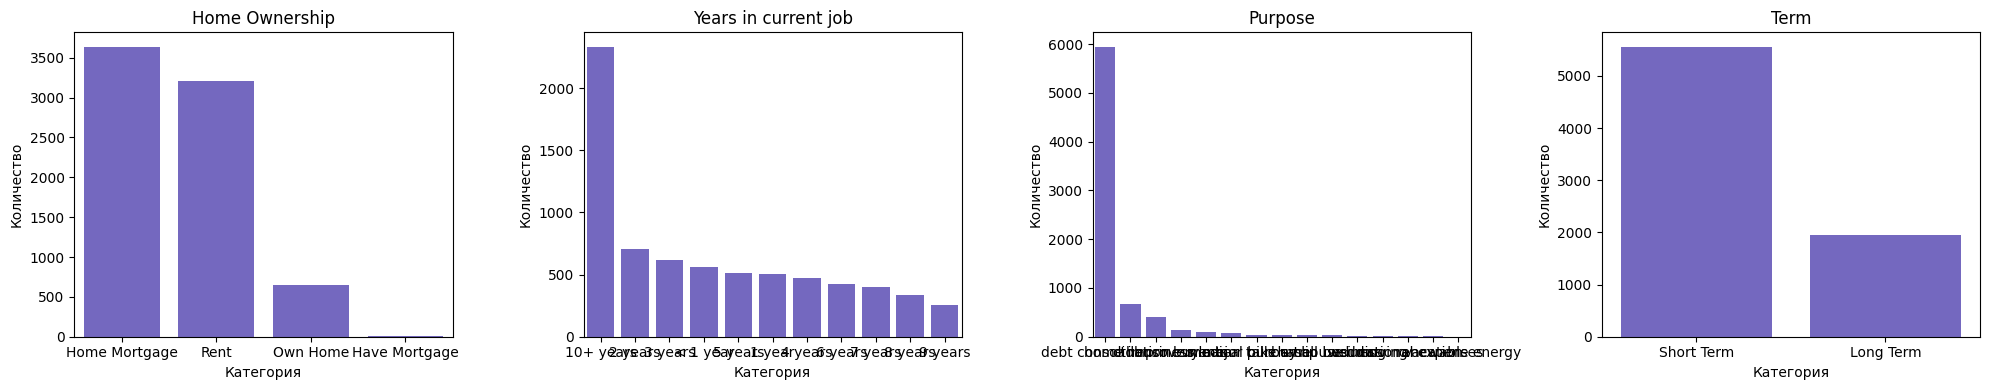

In [5]:
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()
print('Категориальные признаки:')

for column in categorical_features:
    print(f'\n{column} ({df[column].nunique(dropna=False)} уникальных значений):')
    display(df[column].value_counts(dropna=False).rename('Количество').to_frame())

if categorical_features:
    fig, axes = plt.subplots(1, len(categorical_features), figsize=(5 * len(categorical_features), 4))
    if len(categorical_features) == 1:
        axes = [axes]
    for ax, column in zip(axes, categorical_features):
        sns.countplot(data=df, x=column, order=df[column].value_counts().index, ax=ax, color='slateblue')
        ax.set(title=column, xlabel='Категория', ylabel='Количество')
    plt.tight_layout()
    plt.show()

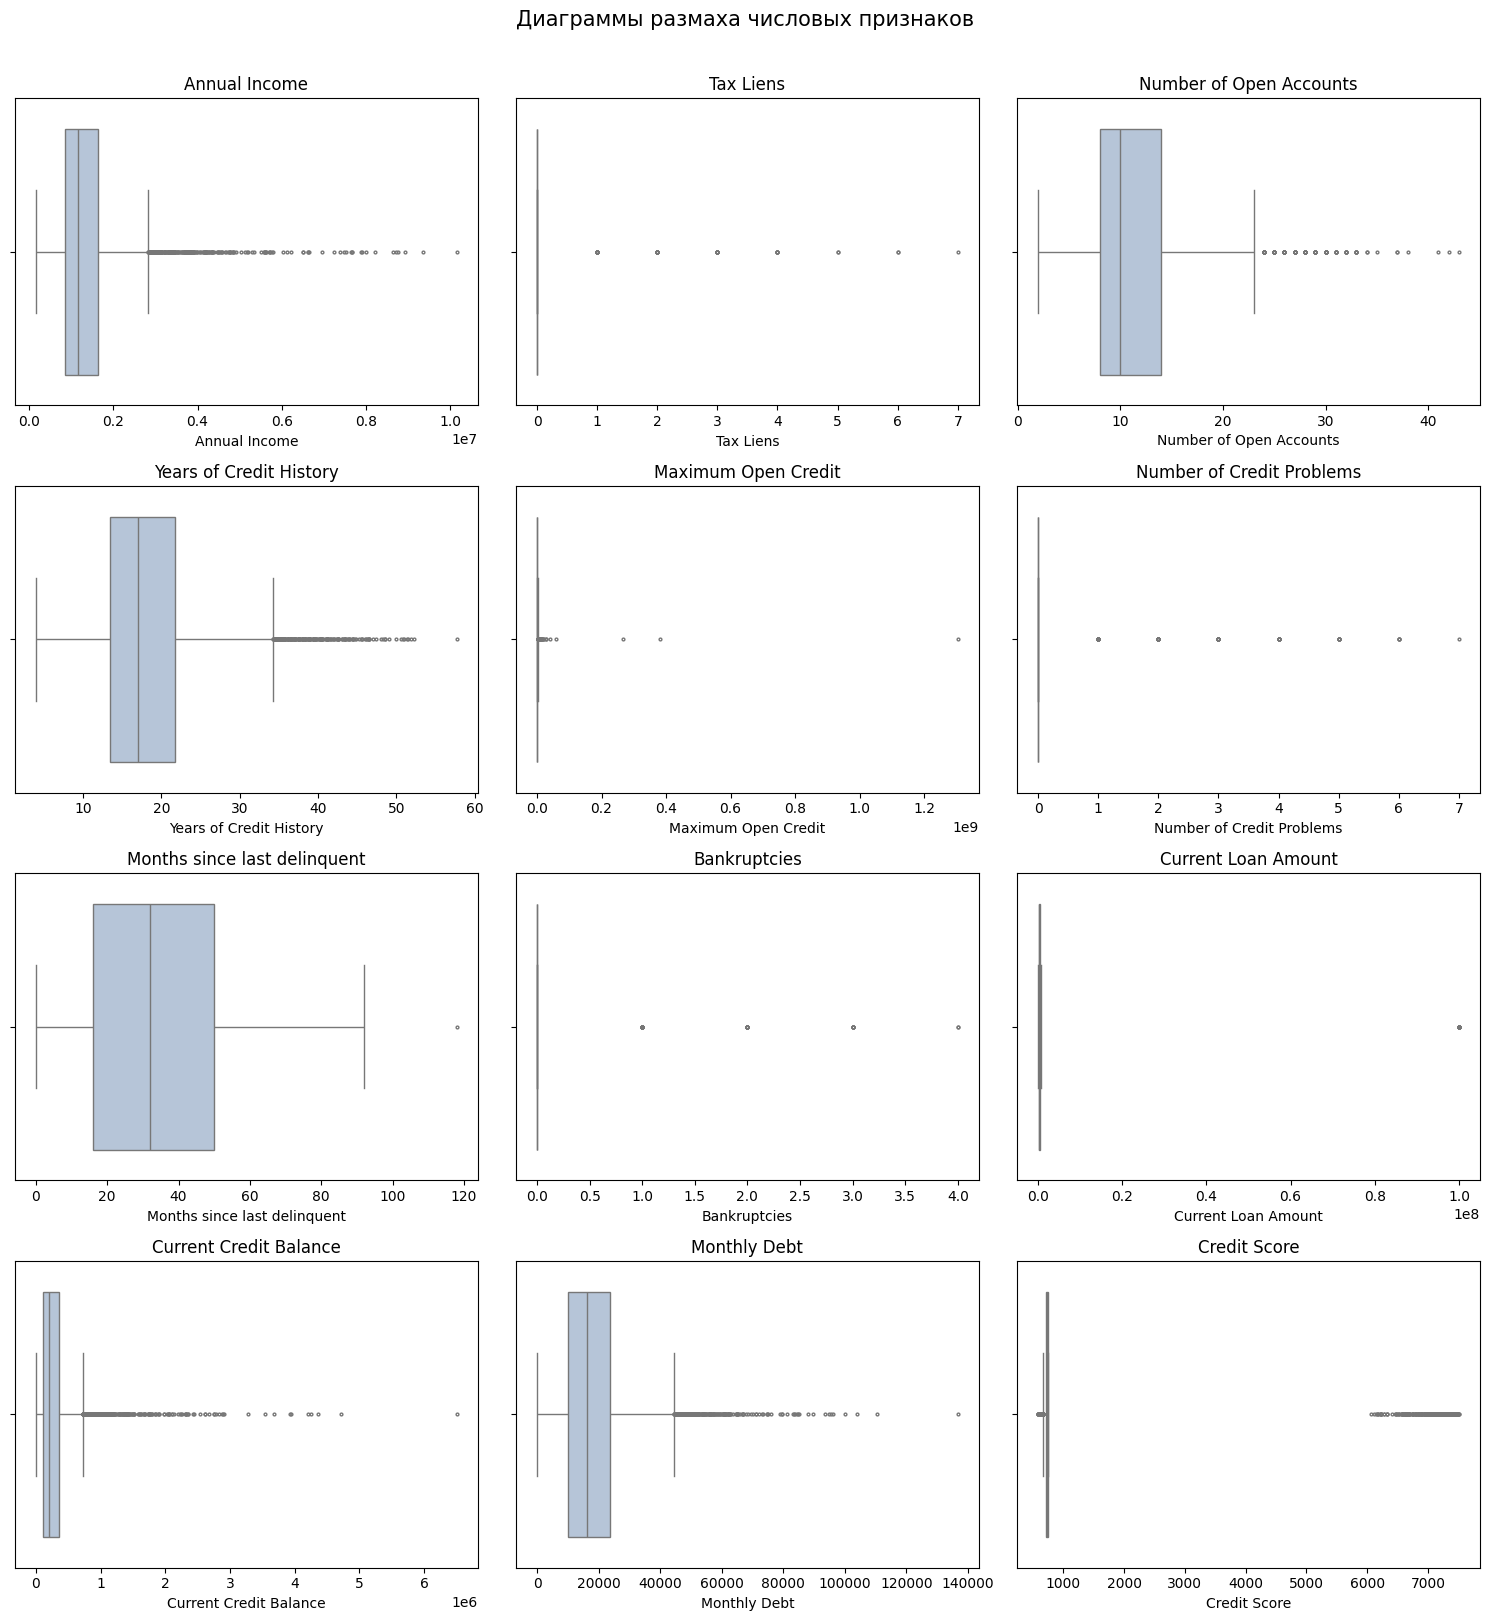

In [6]:
plot_features = [column for column in numeric_features if column != target]
ncols = 3
nrows = (len(plot_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()
for ax, column in zip(axes, plot_features):
    sns.boxplot(x=df[column], ax=ax, color='lightsteelblue', fliersize=2)
    ax.set_title(column)
for ax in axes[len(plot_features):]:
    ax.set_visible(False)
fig.suptitle('Диаграммы размаха числовых признаков', y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

